# Human Action Recognition: transfer learning with MobileNetV2
Classify images into 15 human actions using the HAR dataset (Nagadia, Kaggle) and a MobileNetV2 (Sandler et al., 2018) backbone pretrained on ImageNet (Deng et al., 2009). Transfer learning reuses ImageNet features, which suits a 12,600-image dataset (Yosinski et al., 2014).

## 0. Setup
The first cell runs on Kaggle (clones the repo, finds the dataset) or locally, and silences TensorFlow log noise so the training output stays readable.

In [1]:
import os, sys, glob, subprocess, warnings
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

if os.path.exists("/kaggle/input"):
    REPO = Path("/kaggle/working/Human_Action_Recognition-mlops")
    if not REPO.exists():
        subprocess.run(["git", "clone", "https://github.com/s-gasaro/Human_Action_Recognition-mlops", str(REPO)], check=True)
    csv = glob.glob("/kaggle/input/**/Training_set.csv", recursive=True)[0]
    IMAGE_DIR = Path(csv).parent / "train"
    ON_KAGGLE = True
else:
    REPO = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
    IMAGE_DIR = REPO / "data" / "train"
    ON_KAGGLE = False

sys.path.insert(0, str(REPO / "src"))
SPLITS_CSV = REPO / "data" / "splits.csv"
MODELS_DIR = REPO / "models"
print(REPO, IMAGE_DIR, ON_KAGGLE)

Cloning into '/kaggle/working/Human_Action_Recognition-mlops'...


/kaggle/working/Human_Action_Recognition-mlops /kaggle/input/datasets/meetnagadia/human-action-recognition-har-dataset/Human Action Recognition/train True


**Result:** the paths point to the repo, the training images and `data/splits.csv`; `ON_KAGGLE` decides where the model is saved at the end.

## 1. Data loading
Load the stratified 70/15/15 split built by `src/preprocessing.py` (seed 42), so every experiment uses the same train/val/test images. The test set is only used for the final evaluation.

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
from PIL import Image
import preprocessing as pp
import model as hm

tf.get_logger().setLevel("ERROR")
df = pp.load_splits(SPLITS_CSV)
class_names = pp.get_class_names(df)
train_df, val_df, test_df = [df[df.split == s] for s in ("train", "val", "test")]
print(len(train_df), len(val_df), len(test_df), len(class_names))
print("GPUs:", tf.config.list_physical_devices("GPU"))

8820 1890 1890 15
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


**Result:** 8,820 / 1,890 / 1,890 images for train / val / test over 15 classes. Check that a GPU is listed above before training.

## 2. Exploratory data analysis
### Class distribution
Check class balance, since imbalance would make accuracy misleading and call for class weights.

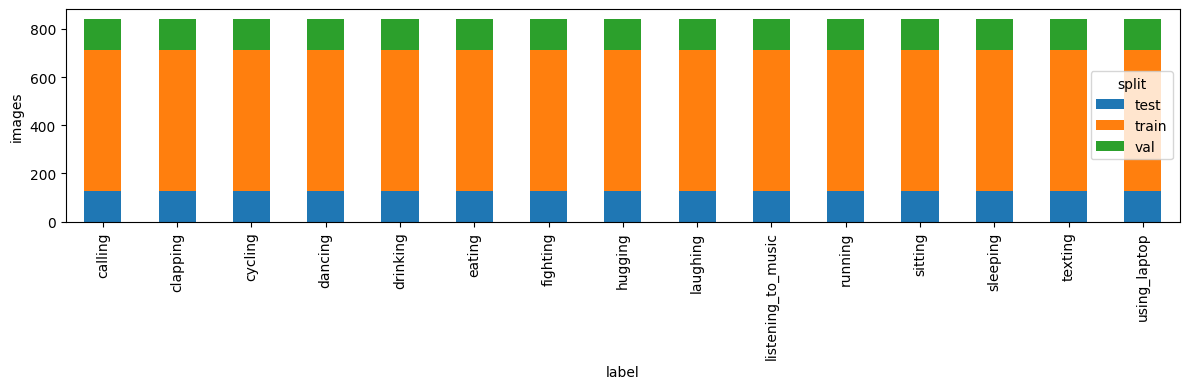

In [3]:
df.groupby(["label", "split"]).size().unstack().plot(kind="bar", stacked=True, figsize=(12, 4))
plt.ylabel("images"); plt.tight_layout(); plt.show()

**Result:** the dataset is balanced: every class has 840 images, split evenly across train/val/test. No class weighting is needed.

### Sample image per class
Look at one image per class to see how varied the scenes are.

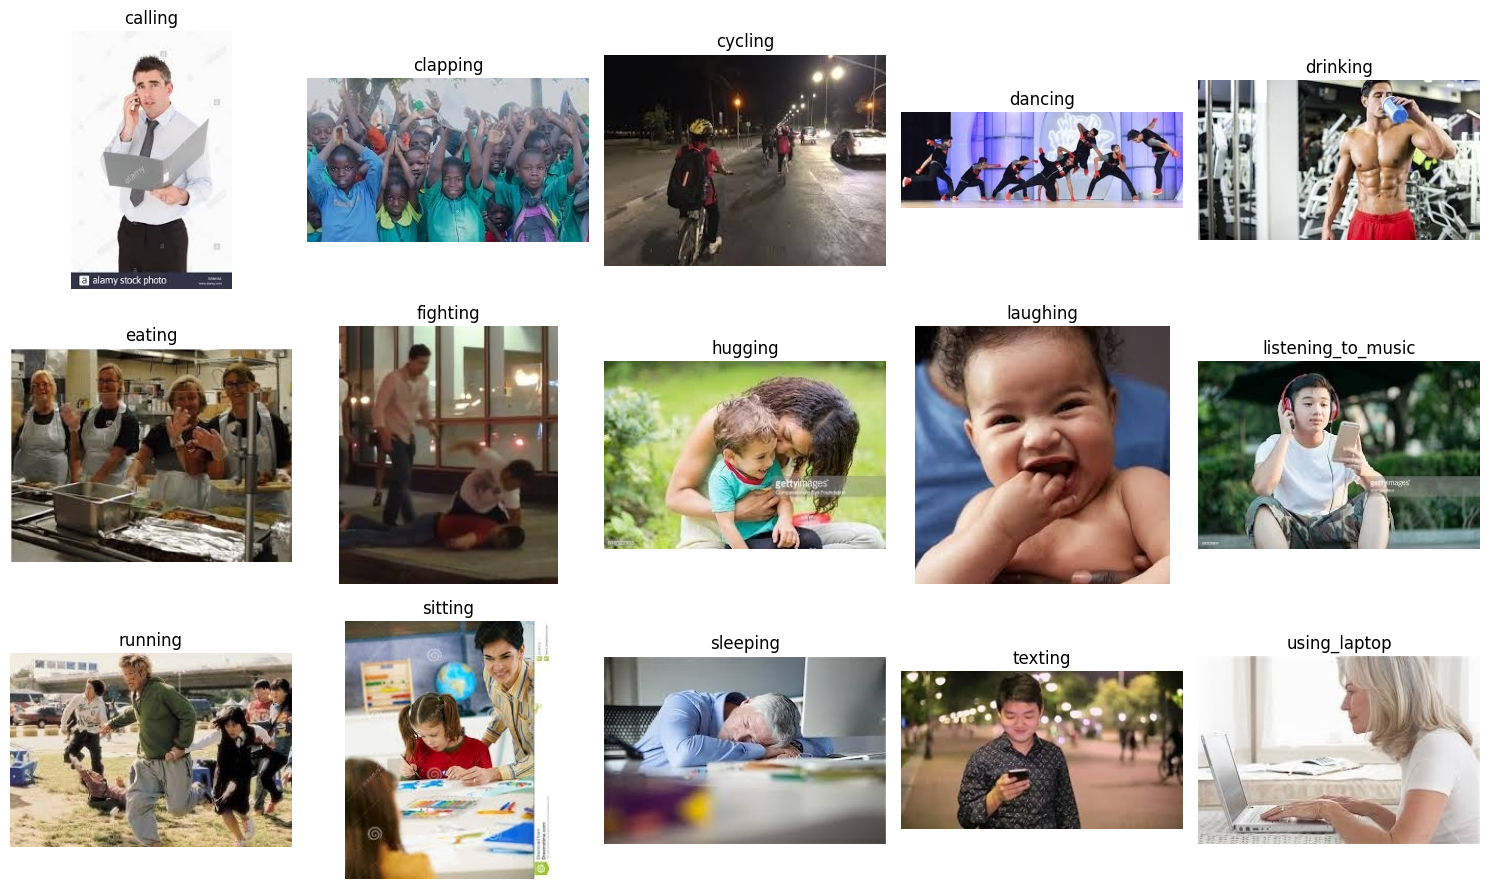

In [4]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for ax, c in zip(axes.ravel(), class_names):
    f = train_df[train_df.label == c].sample(1, random_state=0).filename.iloc[0]
    ax.imshow(Image.open(IMAGE_DIR / f)); ax.set_title(c); ax.axis("off")
plt.tight_layout(); plt.show()

**Result:** one training example per class, to judge variety in background, framing and pose before choosing the augmentation.

### Image size and aspect ratio
Measure the raw sizes (1,000 random training images) to decide how to resize to 224x224.

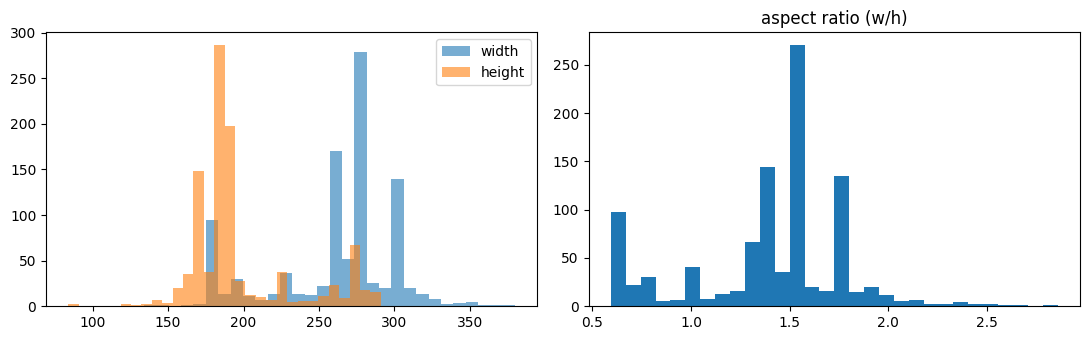

median size (w, h): [275. 183.] | landscape share: 0.804


In [5]:
sample = train_df.sample(1000, random_state=0)
sizes = np.array([Image.open(IMAGE_DIR / f).size for f in sample.filename])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(sizes[:, 0], bins=30, alpha=.6, label="width"); ax[0].hist(sizes[:, 1], bins=30, alpha=.6, label="height"); ax[0].legend()
ax[1].hist(sizes[:, 0] / sizes[:, 1], bins=30); ax[1].set_title("aspect ratio (w/h)")
plt.tight_layout(); plt.show()
print("median size (w, h):", np.median(sizes, axis=0), "| landscape share:", (sizes[:, 0] > sizes[:, 1]).mean())

**Result:** images are small (median about 275x183) and mostly landscape (about 80%, median aspect ratio 1.5). Resizing to a 224x224 square therefore squeezes the width, and the pipeline does not preserve the aspect ratio.

### Brightness per class
Check whether lighting differs by class, which a model could pick up as a shortcut (20 images per class, mean gray level 0-255).

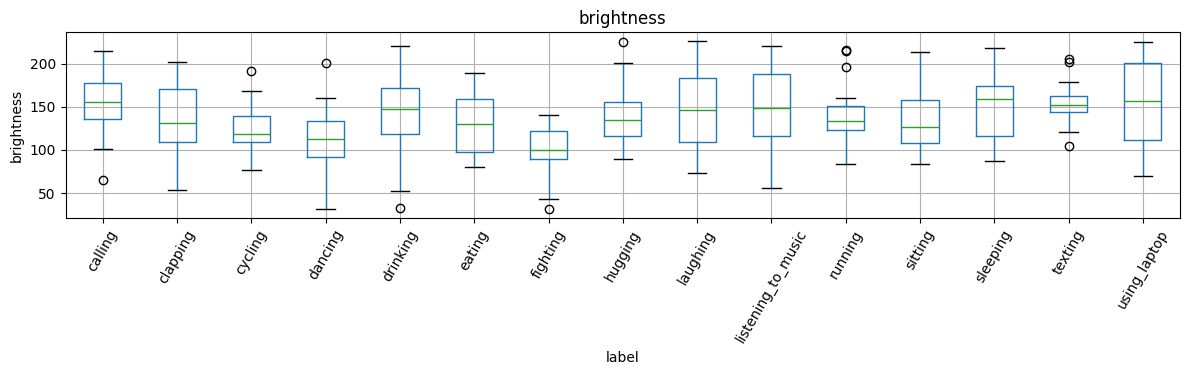

{'fighting': 100.0, 'dancing': 110.0, 'cycling': 123.0, 'eating': 132.0, 'clapping': 136.0, 'sitting': 136.0, 'hugging': 140.0, 'drinking': 140.0, 'running': 141.0, 'laughing': 145.0, 'listening_to_music': 148.0, 'using_laptop': 150.0, 'sleeping': 151.0, 'texting': 154.0, 'calling': 156.0}


In [6]:
rows = []
for c in class_names:
    for f in train_df[train_df.label == c].sample(20, random_state=0).filename:
        rows.append((c, np.asarray(Image.open(IMAGE_DIR / f).convert("L").resize((64, 64))).mean()))
b = pd.DataFrame(rows, columns=["label", "brightness"])
b.boxplot(by="label", column="brightness", figsize=(12, 4), rot=60); plt.suptitle(""); plt.ylabel("brightness"); plt.tight_layout(); plt.show()
print(b.groupby("label").brightness.mean().round(0).sort_values().to_dict())

**Result:** class means range from about 100 (`fighting`) to about 156 (`calling`), but the boxes overlap heavily. Brightness varies within each class more than between classes, so it is unlikely to be a strong shortcut.

## 3. Preprocessing and augmentation
Images are resized to 224x224 and scaled to [-1, 1] with MobileNetV2 `preprocess_input`. Augmentation is applied to training data only and is deliberately light: horizontal flip, rotation up to 5% of a turn and zoom up to 5%.

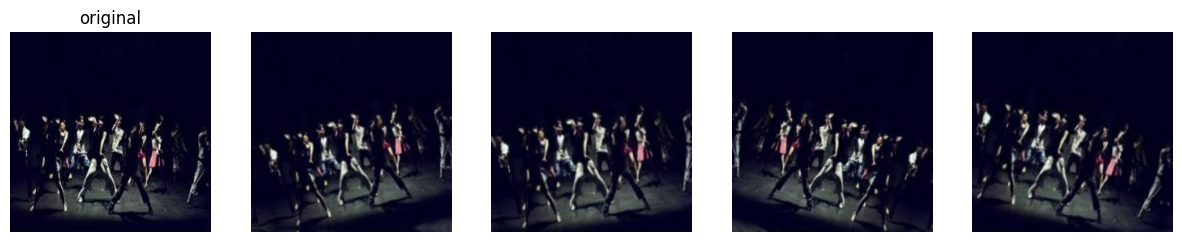

In [7]:
aug = pp.augmentation()
f = train_df.filename.iloc[0]
img = tf.image.resize(tf.io.decode_image(tf.io.read_file(str(IMAGE_DIR / f)), channels=3, expand_animations=False), pp.IMG_SIZE)[None]
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(img[0].numpy().astype("uint8")); axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(aug(img, training=True)[0].numpy().astype("uint8"))
for ax in axes: ax.axis("off")
plt.show()

make = lambda d, **k: pp.make_dataset(d, class_names, IMAGE_DIR, **k)
val_ds, test_ds = make(val_df), make(test_df)
train_plain = make(train_df, training=True, augment=False)
train_aug = make(train_df, training=True, augment=True)

**Result:** the augmented copies stay recognisable and differ only slightly from the original. `train_plain` (shuffled, no augmentation) and `train_aug` (shuffled, augmented) are built for the experiments.

## 4. Experiments
All models are MobileNetV2 with global average pooling, dropout and a 15-way softmax. They are compared on the validation set; training uses EarlyStopping and ReduceLROnPlateau from `src/model.py`. The helper below evaluates each model, plots its loss and accuracy curves and prints the best epoch and the train-validation accuracy gap at that epoch (a large gap means overfitting).

In [8]:
results, models, histories = {}, {}, {}

def log(name, m, hist):
    h = hist.history
    results[name], models[name], histories[name] = hm.evaluate(m, val_ds), m, h
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    for a, k in zip(ax, ("loss", "accuracy")):
        a.plot(h[k], label="train"); a.plot(h["val_" + k], label="val")
        a.set_title(f"{name}: {k}"); a.set_xlabel("epoch"); a.legend()
    plt.tight_layout(); plt.show()
    r, e = results[name], int(np.argmin(h["val_loss"]))
    print(f"{name}: val F1 {r['f1']:.3f}, val acc {r['accuracy']:.3f}, best val_loss at epoch {e + 1}/{len(h['loss'])}, "
          f"train-val acc gap there {h['accuracy'][e] - h['val_accuracy'][e]:+.3f}")

### Exp 1: frozen base (baseline)
Train only the new head on top of the frozen ImageNet features, with no augmentation and no dropout, to get a baseline.

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
276/276 - 92s - 334ms/step - accuracy: 0.5355 - loss: 1.4629 - val_accuracy: 0.6265 - val_loss: 1.1438 - learning_rate: 0.0010
Epoch 2/8
276/276 - 9s - 34ms/step - accuracy: 0.6715 - loss: 1.0056 - val_accuracy: 0.6571 - val_loss: 1.0691 - learning_rate: 0.0010
Epoch 3/8
276/276 - 9s - 34ms/step - accuracy: 0.7115 - loss: 0.8910 - val_accuracy: 0.6831 - val_loss: 1.0001 - learning_rate: 0.0010
Epoch 4/8
276/276 - 9s - 34ms/step - accuracy: 0.7397 - loss: 0.8102 - val_accuracy: 0.6767 - val_loss: 1.0263 - learning_rate: 0.0010
Epoch 5/8
276/276 - 9s - 34ms/step - accuracy: 0.7542 - loss: 0.7489 - val_accuracy: 0.6862 - val_loss: 1.0150 - learning_rate: 0.0010
Epoch 6/8
276/276 - 10s - 35ms/step - accuracy: 0.7949 - loss: 0.6529 - val_accuracy: 0.6952 - val_loss: 0.9853 - learning_rate: 3.0000e-04
Epoch 7/8
276/276 - 10s - 35ms/step - accuracy: 0.8017 - loss: 0.6377 - val_accuracy: 0.6862 - val_loss: 0.9898 - learning_rate: 3.000

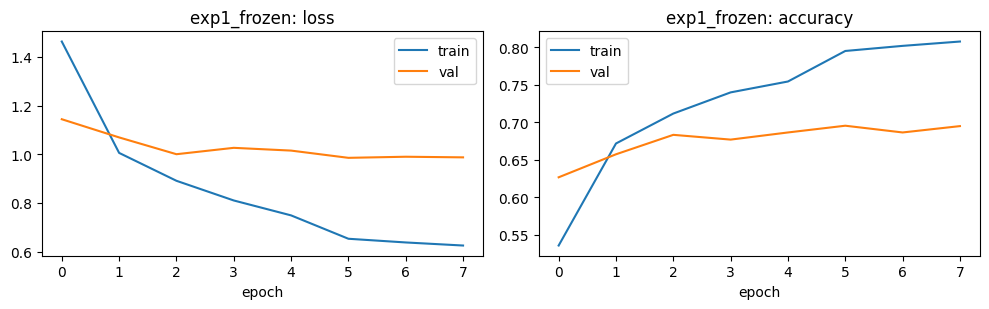

exp1_frozen: val F1 0.695, val acc 0.695, best val_loss at epoch 6/8, train-val acc gap there +0.100


In [9]:
m1 = hm.build_model(len(class_names), dropout=0.0, lr=1e-3)
h1 = hm.train(m1, train_plain, val_ds, epochs=8)
log("exp1_frozen", m1, h1)

**Conclusion:** baseline with validation F1 0.695 at best epoch 6 of 8. The train-validation gap is 0.10, so the head overfits.

### Exp 2: frozen base + light augmentation + dropout 0.3
Same frozen setup as exp 1 plus the light augmentation and dropout 0.3, to see whether regularisation reduces the overfitting.

Epoch 1/10
276/276 - 64s - 231ms/step - accuracy: 0.4382 - loss: 1.7903 - val_accuracy: 0.6053 - val_loss: 1.2381 - learning_rate: 0.0010
Epoch 2/10
276/276 - 46s - 168ms/step - accuracy: 0.5804 - loss: 1.2937 - val_accuracy: 0.6339 - val_loss: 1.1011 - learning_rate: 0.0010
Epoch 3/10
276/276 - 47s - 169ms/step - accuracy: 0.6139 - loss: 1.2115 - val_accuracy: 0.6614 - val_loss: 1.0574 - learning_rate: 0.0010
Epoch 4/10
276/276 - 81s - 294ms/step - accuracy: 0.6279 - loss: 1.1431 - val_accuracy: 0.6365 - val_loss: 1.1097 - learning_rate: 0.0010
Epoch 5/10
276/276 - 45s - 165ms/step - accuracy: 0.6358 - loss: 1.1139 - val_accuracy: 0.6561 - val_loss: 1.0519 - learning_rate: 0.0010
Epoch 6/10
276/276 - 46s - 166ms/step - accuracy: 0.6454 - loss: 1.0843 - val_accuracy: 0.6635 - val_loss: 1.0654 - learning_rate: 0.0010
Epoch 7/10
276/276 - 45s - 164ms/step - accuracy: 0.6544 - loss: 1.0666 - val_accuracy: 0.6661 - val_loss: 1.0294 - learning_rate: 0.0010
Epoch 8/10
276/276 - 45s - 164ms/s

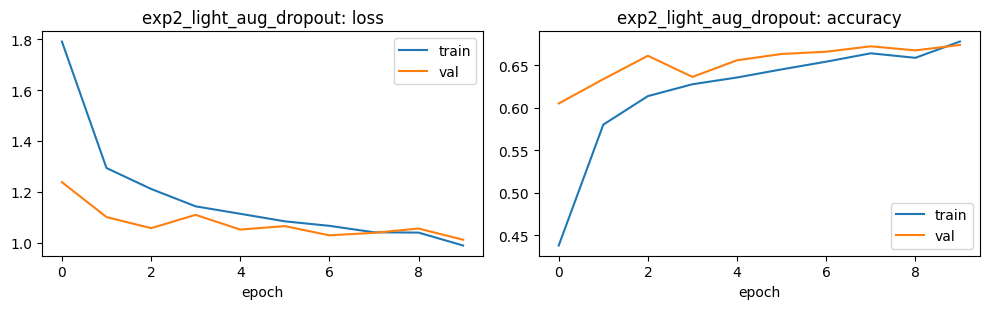

exp2_light_aug_dropout: val F1 0.673, val acc 0.674, best val_loss at epoch 10/10, train-val acc gap there +0.004


In [10]:
m2 = hm.build_model(len(class_names), dropout=0.3, lr=1e-3)
h2 = hm.train(m2, train_aug, val_ds, epochs=10)
log("exp2_light_aug_dropout", m2, h2)

**Conclusion:** val F1 0.673 with a gap of only 0.004. Regularisation removed the overfitting but lowered F1 (0.695 to 0.673), so the frozen features, not overfitting, limit accuracy.

### Exp 3: fine-tune the top 50 layers from exp 1 (LR 1e-5)
Copy the exp 1 model, unfreeze the top 50 layers of MobileNetV2 and continue with a very low learning rate (1e-5) so the pretrained weights are adjusted without being destroyed. It uses the unaugmented data of exp 1, up to 15 epochs with early stopping.

Epoch 1/15
276/276 - 56s - 202ms/step - accuracy: 0.6387 - loss: 1.1129 - val_accuracy: 0.6746 - val_loss: 1.0152 - learning_rate: 1.0000e-05
Epoch 2/15
276/276 - 14s - 49ms/step - accuracy: 0.7268 - loss: 0.8526 - val_accuracy: 0.6778 - val_loss: 0.9952 - learning_rate: 1.0000e-05
Epoch 3/15
276/276 - 14s - 50ms/step - accuracy: 0.7709 - loss: 0.7291 - val_accuracy: 0.6910 - val_loss: 0.9736 - learning_rate: 1.0000e-05
Epoch 4/15
276/276 - 13s - 49ms/step - accuracy: 0.7989 - loss: 0.6456 - val_accuracy: 0.6989 - val_loss: 0.9569 - learning_rate: 1.0000e-05
Epoch 5/15
276/276 - 13s - 48ms/step - accuracy: 0.8342 - loss: 0.5607 - val_accuracy: 0.7037 - val_loss: 0.9475 - learning_rate: 1.0000e-05
Epoch 6/15
276/276 - 13s - 48ms/step - accuracy: 0.8539 - loss: 0.4915 - val_accuracy: 0.6995 - val_loss: 0.9368 - learning_rate: 1.0000e-05
Epoch 7/15
276/276 - 13s - 48ms/step - accuracy: 0.8766 - loss: 0.4364 - val_accuracy: 0.7048 - val_loss: 0.9339 - learning_rate: 1.0000e-05
Epoch 8/15
2

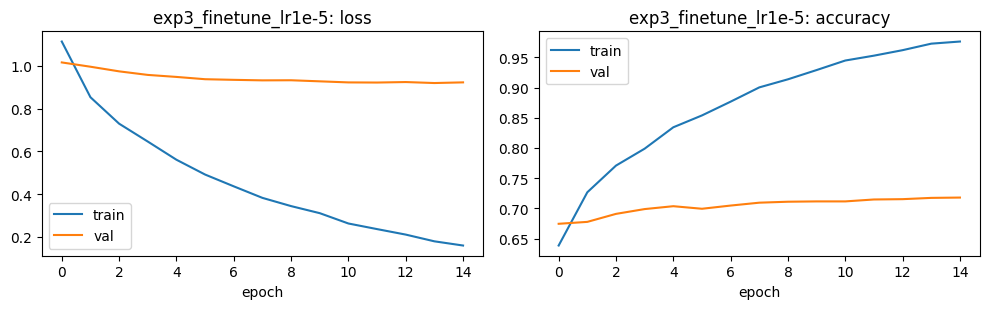

exp3_finetune_lr1e-5: val F1 0.716, val acc 0.717, best val_loss at epoch 14/15, train-val acc gap there +0.255


In [11]:
m3 = tf.keras.models.clone_model(m1)
m3.set_weights(m1.get_weights())
hm.unfreeze(m3, 50, lr=1e-5)
h3 = hm.train(m3, train_plain, val_ds, epochs=15)
log("exp3_finetune_lr1e-5", m3, h3)

**Conclusion:** val F1 0.716, better than exp 1 and still improving at epoch 14 of 15, so adapting the top layers helps and more epochs could help further.

### Exp 4: same fine-tune with LR 1e-4
Repeat exp 3 from exp 1 with a 10x higher learning rate (1e-4) to find out how sensitive fine-tuning is to the learning rate.

Epoch 1/15
276/276 - 46s - 167ms/step - accuracy: 0.6971 - loss: 0.9318 - val_accuracy: 0.6540 - val_loss: 1.1937 - learning_rate: 1.0000e-04
Epoch 2/15
276/276 - 14s - 50ms/step - accuracy: 0.8974 - loss: 0.3625 - val_accuracy: 0.6746 - val_loss: 1.1388 - learning_rate: 1.0000e-04
Epoch 3/15
276/276 - 14s - 50ms/step - accuracy: 0.9687 - loss: 0.1569 - val_accuracy: 0.6915 - val_loss: 1.1016 - learning_rate: 1.0000e-04
Epoch 4/15
276/276 - 13s - 48ms/step - accuracy: 0.9918 - loss: 0.0705 - val_accuracy: 0.7048 - val_loss: 1.0801 - learning_rate: 1.0000e-04
Epoch 5/15
276/276 - 13s - 48ms/step - accuracy: 0.9973 - loss: 0.0364 - val_accuracy: 0.7153 - val_loss: 1.0747 - learning_rate: 1.0000e-04
Epoch 6/15
276/276 - 13s - 48ms/step - accuracy: 0.9985 - loss: 0.0241 - val_accuracy: 0.7317 - val_loss: 1.0606 - learning_rate: 1.0000e-04
Epoch 7/15
276/276 - 13s - 48ms/step - accuracy: 0.9988 - loss: 0.0177 - val_accuracy: 0.7370 - val_loss: 1.0637 - learning_rate: 1.0000e-04
Epoch 8/15
2

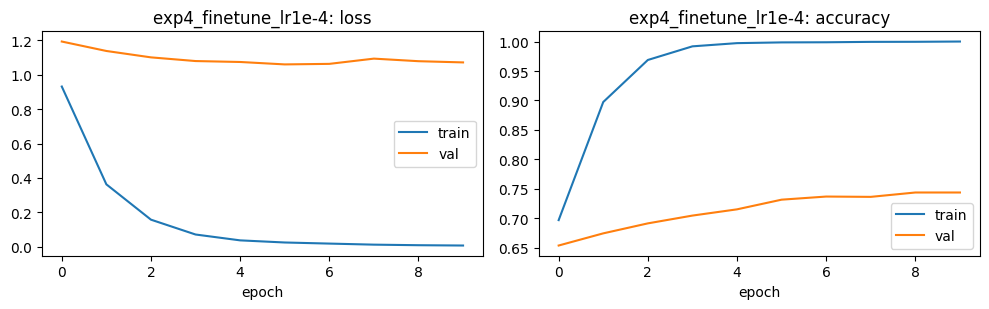

exp4_finetune_lr1e-4: val F1 0.728, val acc 0.732, best val_loss at epoch 6/10, train-val acc gap there +0.267


In [12]:
m4 = tf.keras.models.clone_model(m1)
m4.set_weights(m1.get_weights())
hm.unfreeze(m4, 50, lr=1e-4)
h4 = hm.train(m4, train_plain, val_ds, epochs=15)
log("exp4_finetune_lr1e-4", m4, h4)

**Conclusion:** val F1 0.728, the best result (+0.033 over the baseline), at best epoch 6. The gap is large (0.27) and the validation loss is higher than the baseline (1.06 vs 0.92): the model is more accurate but less calibrated. Early stopping restored the best weights.

In [13]:
table = pd.DataFrame(results).T[["accuracy", "loss", "precision", "recall", "f1"]]
display(table.round(4))
best_name = table["f1"].idxmax()
best = models[best_name]
print(f"Best: {best_name} (val F1 {table.f1.max():.3f}, {table.f1.max() - table.loc['exp1_frozen', 'f1']:+.3f} vs the exp 1 baseline)")

,accuracy,loss,precision,recall,f1
exp1_frozen,0.6952,0.9853,0.6977,0.6952,0.6947
exp2_light_aug_dropout,0.6741,1.0120,0.6853,0.6741,0.6730
exp3_finetune_lr1e-5,0.7175,0.9190,0.7184,0.7175,0.7159
exp4_finetune_lr1e-4,0.7317,1.0606,0.7411,0.7317,0.7277


Best: exp4_finetune_lr1e-4 (val F1 0.728, +0.033 vs the exp 1 baseline)


**Conclusion:** exp 4 (fine-tuning at LR 1e-4) is selected with val macro F1 0.728, 0.033 above the frozen baseline.

{'accuracy': 0.7428571581840515, 'loss': 1.0658520460128784, 'precision': 0.7537473826905265, 'recall': 0.7428571428571428, 'f1': 0.7395513756062688}
                    precision    recall  f1-score   support

           calling       0.58      0.65      0.61       126
          clapping       0.68      0.79      0.73       126
           cycling       0.99      0.94      0.97       126
           dancing       0.70      0.85      0.77       126
          drinking       0.66      0.85      0.74       126
            eating       0.88      0.78      0.83       126
          fighting       0.89      0.73      0.80       126
           hugging       0.77      0.84      0.81       126
          laughing       0.73      0.80      0.76       126
listening_to_music       0.71      0.51      0.59       126
           running       0.84      0.91      0.87       126
           sitting       0.53      0.60      0.57       126
          sleeping       0.88      0.79      0.84       126
         

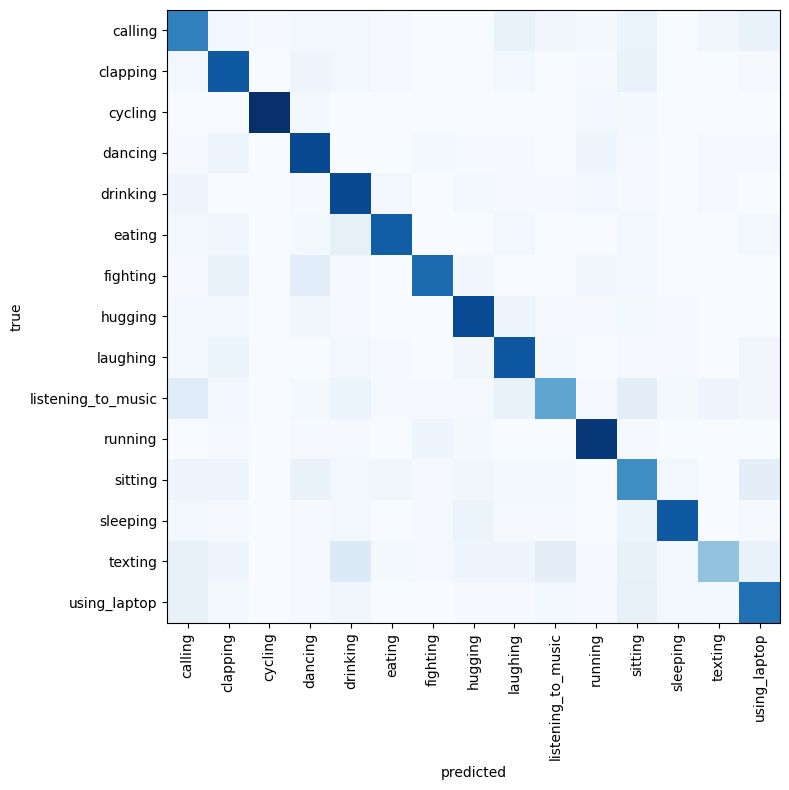

In [14]:
from collections import Counter
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support
test_metrics = hm.evaluate(best, test_ds)
print(test_metrics)
y_true = np.concatenate([y.numpy().argmax(1) for _, y in test_ds])
y_pred = best.predict(test_ds, verbose=0).argmax(1)
print(classification_report(y_true, y_pred, target_names=class_names))
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(cm, cmap="Blues"); ax.set_xticks(range(len(class_names)), class_names, rotation=90); ax.set_yticks(range(len(class_names)), class_names)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); plt.tight_layout(); plt.show()

**Conclusion:** test accuracy 0.74 and macro F1 0.74, close to the validation F1 of 0.728, so model selection did not overfit the validation set. Bright cells off the diagonal are the confused class pairs.

### Per-class F1
Rank classes by F1 to find where the model is weakest.

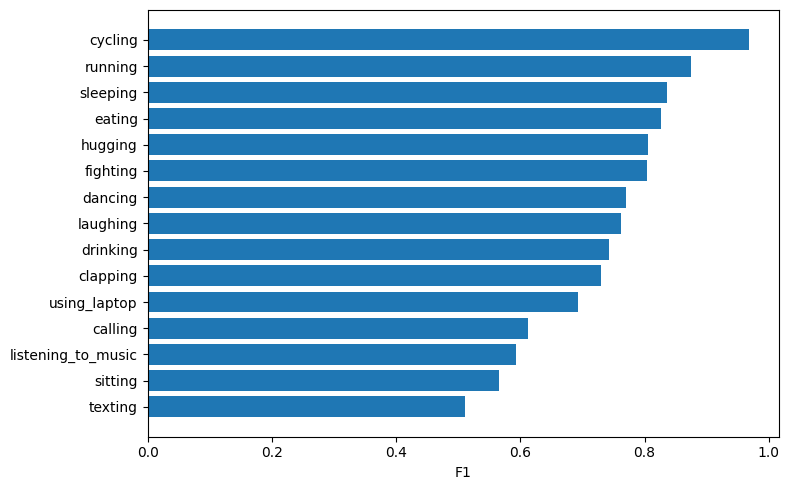

Lowest F1: {'texting': 0.51, 'sitting': 0.57, 'listening_to_music': 0.59}


In [15]:
f1s = precision_recall_fscore_support(y_true, y_pred, labels=range(len(class_names)), zero_division=0)[2]
order = np.argsort(f1s)
plt.figure(figsize=(8, 5)); plt.barh([class_names[i] for i in order], f1s[order]); plt.xlabel("F1"); plt.tight_layout(); plt.show()
print("Lowest F1:", {class_names[i]: round(float(f1s[i]), 2) for i in order[:3]})

**Conclusion:** the weakest classes are `texting` (F1 0.51, recall 0.38), `sitting` (0.57) and `listening_to_music` (0.59). Collecting more varied examples of these classes through the upload/retrain flow is the most direct way to improve them.

### Misclassified test images
Look at errors directly: 12 random misclassified test images with true and predicted labels, and the most frequent confusions.

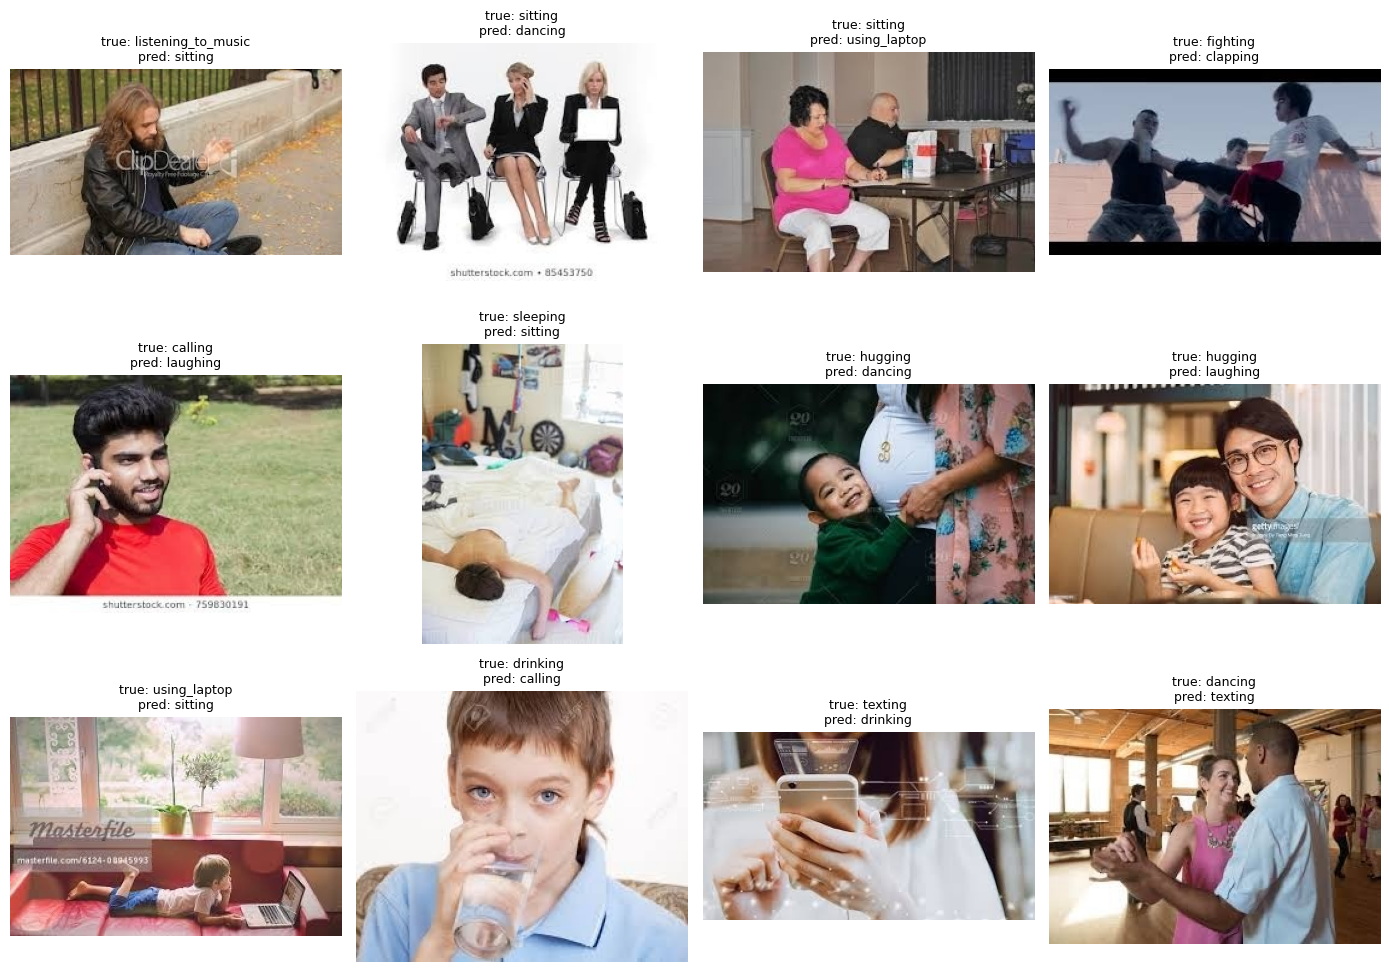

[(('texting', 'drinking'), 16), (('listening_to_music', 'calling'), 14), (('fighting', 'dancing'), 13), (('texting', 'listening_to_music'), 12), (('listening_to_music', 'sitting'), 12)]


In [16]:
wrong = np.where(y_true != y_pred)[0]
pick = np.random.default_rng(0).choice(wrong, min(12, len(wrong)), replace=False)
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax in axes.ravel(): ax.axis("off")
for ax, i in zip(axes.ravel(), pick):
    ax.imshow(Image.open(IMAGE_DIR / test_df.iloc[i].filename))
    ax.set_title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]}", fontsize=9)
plt.tight_layout(); plt.show()
print(Counter((class_names[t], class_names[p]) for t, p in zip(y_true[wrong], y_pred[wrong])).most_common(5))

**Conclusion:** the top confusions are `texting` as `drinking` (16), `listening_to_music` as `calling` (14) and `fighting` as `dancing` (13). Poses with a hand near the face look alike in still images.

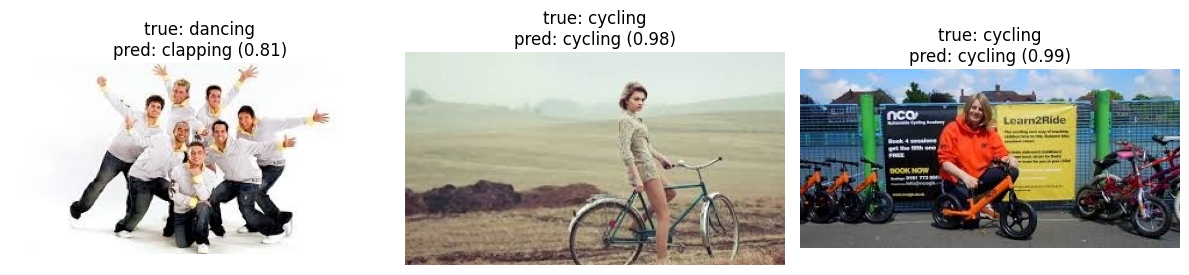

In [17]:
from prediction import predict

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (_, r) in zip(axes, test_df.sample(3, random_state=1).iterrows()):
    res = predict(IMAGE_DIR / r.filename, best, class_names)
    ax.imshow(Image.open(IMAGE_DIR / r.filename)); ax.axis("off")
    ax.set_title(f"true: {r.label}\npred: {res['label']} ({res['confidence']:.2f})")
plt.tight_layout(); plt.show()

**Conclusion:** each title shows the true label, the predicted label and the model's confidence; `predict()` also returns the top-3 classes, which the API exposes.

## 8. Save the best model
Save the model, class names and metadata (experiment name and test metrics) with `save_model` to `models/`, and also to `/kaggle/working/models` on Kaggle so they can be downloaded.

In [18]:
meta = {"experiment": best_name, **test_metrics}
hm.save_model(best, class_names, meta, MODELS_DIR)
if ON_KAGGLE:
    hm.save_model(best, class_names, meta, "/kaggle/working/models")
print(os.listdir(MODELS_DIR))

['har_model.h5', 'class_names.json', 'metadata.json']


**Conclusion:** `har_model.h5`, `class_names.json` and `metadata.json` are the files the FastAPI service loads and that retraining replaces when a new version is promoted.

## 9. Discussion
The first Kaggle run (heavier augmentation, fine-tuning from the augmented model) did not beat the frozen baseline, which motivated lighter augmentation and fine-tuning from the baseline.

Fine-tuning the top 50 layers gave the best model: validation F1 0.728 at LR 1e-4 against 0.695 for the frozen baseline, and 0.716 at LR 1e-5. Regularising the frozen model removed its overfitting (gap 0.004) but lowered F1 to 0.673, so frozen features limit accuracy. The higher learning rate overfits more (gap 0.27, validation loss 1.06 vs 0.92), so it is more accurate but less calibrated. On the test set the model reaches accuracy 0.74 and macro F1 0.74, in line with validation.

Errors concentrate on classes that look alike in a still image: `texting` (F1 0.51), `sitting` (0.57) and `listening_to_music` (0.59), with hand-near-face confusions such as `texting` as `drinking` and `listening_to_music` as `calling`. Likely improvements are more varied images of weak classes (via the retrain flow), aspect-preserving resizing, longer fine-tuning at LR 1e-5 and a larger backbone.

## References
- Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., Chen, L.-C. (2018). MobileNetV2: Inverted Residuals and Linear Bottlenecks. CVPR 2018.
- Deng, J., Dong, W., Socher, R., Li, L.-J., Li, K., Fei-Fei, L. (2009). ImageNet: A large-scale hierarchical image database. CVPR 2009.
- Yosinski, J., Clune, J., Bengio, Y., Lipson, H. (2014). How transferable are features in deep neural networks? NeurIPS 2014.
- Nagadia, M. Human Action Recognition (HAR) Dataset. Kaggle. https://www.kaggle.com/datasets/meetnagadia/human-action-recognition-har-dataset